# SafeRoute — Modelo de Predição de Acidentes Fatais

**Sprint 2 — versão consolidada.** Notebook linear: rode de cima para baixo
(`Ambiente de execução → Executar tudo`) sem estado oculto. Cada variável é
definida uma única vez.

Pipeline: carga → limpeza → engenharia de atributos → target binário (fatal vs
não-fatal) → divisão treino/teste → treino → avaliação → conclusões (importância
de atributos e cruzamentos).


## 1. Importações e carregamento dos dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay, precision_recall_curve
)

# imbalanced-learn (oversampling só no treino)
!pip install -q imbalanced-learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

sns.set_style("whitegrid")

In [ ]:
ARQUIVO = "datatran2026.csv"

df = pd.read_csv('datatran2025.csv', sep=";", encoding="latin1", low_memory=False)

print(f"Registros: {df.shape[0]:,} | Colunas: {df.shape[1]}")
df.head()

Registros: 72,529 | Colunas: 30


,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,652493,2025-01-01,quarta-feira,06:20:00,SP,116,225,GUARULHOS,Reação tardia ou ineficiente do condutor,Tombamento,...,0,0,1,1,2,"-23,48586772","-46,54075317",SPRF-SP,DEL01-SP,UOP01-DEL01-SP
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,"546,2",PENAFORTE,Pista esburacada,Colisão frontal,...,0,1,4,1,6,"-7,812288","-39,08333306",SPRF-CE,DEL05-CE,UOP03-DEL05-CE
2,652522,2025-01-01,quarta-feira,08:45:00,PR,369,"88,2",CORNELIO PROCOPIO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,2,0,3,2,"-23,182565","-50,637228",SPRF-PR,DEL07-PR,UOP05-DEL07-PR
3,652544,2025-01-01,quarta-feira,11:00:00,PR,116,74,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,...,0,4,0,1,2,"-25,36517687","-49,04223028",SPRF-PR,DEL01-PR,UOP02-DEL01-PR
4,652549,2025-01-01,quarta-feira,09:30:00,MG,251,471,FRANCISCO SA,Velocidade Incompatível,Colisão frontal,...,1,1,2,2,4,"-16,46801304","-43,43121303",SPRF-MG,DEL12-MG,UOP01-DEL12-MG


## 2. Limpeza e correção de tipos

Corrige o separador decimal (a PRF exporta `latitude`, `longitude` e `km` com
vírgula) e converte a data.

In [ ]:
# Decimal com vírgula -> ponto
for col in ["latitude", "longitude", "km"]:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str).str.replace(",", ".", regex=False),
            errors="coerce"
        )

# Data e hora
df["data_inversa"] = pd.to_datetime(df["data_inversa"], dayfirst=True, errors="coerce")
df["hora"] = pd.to_datetime(df["horario"], format="%H:%M:%S", errors="coerce").dt.hour

# Padroniza o nome da coluna de condição meteorológica (varia entre anos da PRF)
for cand in ["condicao_metereologica", "condicao_meteorologica", "cond_meteorologica"]:
    if cand in df.columns:
        df = df.rename(columns={cand: "condicao_meteorologica"})
        break

print("Limpeza concluída.")

Limpeza concluída.


## 3. Atributos temporais e chave de segmento rodoviário

In [ ]:
# Atributos temporais
df["dia_semana_num"] = df["data_inversa"].dt.dayofweek  # 0 = segunda
df["mes"] = df["data_inversa"].dt.month
df["ano"] = df["data_inversa"].dt.year

# Chave de segmento: BR + faixa de 5 km  (base para o risco por trecho)
TAMANHO_SEGMENTO_KM = 5
df["km_segmento"] = (df["km"] // TAMANHO_SEGMENTO_KM) * TAMANHO_SEGMENTO_KM
df["segmento_id"] = df["br"].astype(str) + "_KM" + df["km_segmento"].astype(str)

print(f"Segmentos únicos: {df['segmento_id'].nunique():,}")

Segmentos únicos: 5,963


## 4. Definição do target binário

Reformulação do problema: em vez de 3 classes (com fronteira ambígua entre
"feridas" e "fatais"), o modelo passa a responder **"este acidente tem risco de
morte?"** — 1 = fatal, 0 = não-fatal. Alinha-se ao objetivo do SafeRoute
(prevenir mortes) e torna o desbalanceamento tratável como problema binário.

In [ ]:
TARGET_ORIGINAL = "classificacao_acidente"

df["target_binario"] = (df[TARGET_ORIGINAL] == "Com Vítimas Fatais").astype(int)

print("Distribuição do target (0 = não-fatal, 1 = fatal):")
print(df["target_binario"].value_counts())
print((df["target_binario"].value_counts(normalize=True) * 100).round(2))

Distribuição do target (0 = não-fatal, 1 = fatal):
target_binario
0    67320
1     5209
Name: count, dtype: int64
target_binario
0    92.82
1     7.18
Name: proportion, dtype: float64


## 5. Seleção de atributos (com remoção de vazamento)

As colunas `mortos`, `feridos*`, `ilesos`, `pessoas` etc. são usadas pela própria
PRF para derivar a classificação — mantê-las seria **vazamento de dados**. Ficam
de fora do treino.

In [ ]:
features_categoricas = [c for c in [
    "causa_acidente", "tipo_acidente", "fase_dia", "condicao_meteorologica",
    "tipo_pista", "tracado_via", "uso_solo", "sentido_via", "uf"
] if c in df.columns]

features_numericas = [c for c in [
    "hora", "mes", "dia_semana_num", "veiculos", "latitude", "longitude"
] if c in df.columns]

print("Categóricas:", features_categoricas)
print("Numéricas:  ", features_numericas)

colunas = features_categoricas + features_numericas + ["segmento_id", "target_binario"]
df_modelo = df[colunas].dropna(subset=["target_binario"]).copy()
print(f"\nRegistros para modelagem: {len(df_modelo):,}")

Categóricas: ['causa_acidente', 'tipo_acidente', 'fase_dia', 'condicao_meteorologica', 'tipo_pista', 'tracado_via', 'uso_solo', 'sentido_via', 'uf']
Numéricas:   ['hora', 'mes', 'dia_semana_num', 'veiculos', 'latitude', 'longitude']

Registros para modelagem: 72,529


## 6. Divisão treino/teste

O split acontece **antes** de calcular o risco por segmento, para não vazar
informação do teste para o treino.

In [ ]:
X = df_modelo[features_categoricas + features_numericas + ["segmento_id"]]
y = df_modelo["target_binario"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Treino: {len(X_train):,} | Teste: {len(X_test):,}")

Treino: 58,023 | Teste: 14,506


## 7. Feature de risco histórico por segmento

Calculada **só com o treino**. Para cada segmento: total de acidentes e taxa de
fatalidade. O risco também é normalizado dentro da própria rodovia
(`risco_relativo_na_br`) — comparando o KM contra os outros KMs da mesma BR, e
não contra o país inteiro (evita falsos positivos entre rodovias muito
diferentes).

In [ ]:
treino_tmp = X_train.copy()
treino_tmp["fatal"] = y_train.values
treino_tmp["br"] = treino_tmp["segmento_id"].str.split("_KM").str[0]

# Estatísticas por segmento
risco_seg = (treino_tmp.groupby("segmento_id")
             .agg(total_acidentes_segmento=("fatal", "count"),
                  taxa_fatalidade_segmento=("fatal", "mean"))
             .reset_index())
risco_seg["br"] = risco_seg["segmento_id"].str.split("_KM").str[0]

# Média de fatalidade por rodovia -> risco relativo dentro da BR
media_br = treino_tmp.groupby("br")["fatal"].mean().rename("media_br")
risco_seg = risco_seg.merge(media_br, on="br", how="left")
risco_seg["risco_relativo_na_br"] = (
    risco_seg["taxa_fatalidade_segmento"] / (risco_seg["media_br"] + 1e-6)
)

media_global = treino_tmp["fatal"].mean()

def aplicar_risco(X_split):
    out = X_split.merge(
        risco_seg[["segmento_id", "total_acidentes_segmento",
                   "taxa_fatalidade_segmento", "risco_relativo_na_br"]],
        on="segmento_id", how="left"
    )
    out["total_acidentes_segmento"] = out["total_acidentes_segmento"].fillna(0)
    out["taxa_fatalidade_segmento"] = out["taxa_fatalidade_segmento"].fillna(media_global)
    out["risco_relativo_na_br"] = out["risco_relativo_na_br"].fillna(1.0)
    return out.drop(columns=["segmento_id"])

X_train = aplicar_risco(X_train)
X_test = aplicar_risco(X_test)

features_numericas += ["total_acidentes_segmento", "taxa_fatalidade_segmento",
                       "risco_relativo_na_br"]
print("Numéricas (atualizadas):", features_numericas)
X_train.head()

Numéricas (atualizadas): ['hora', 'mes', 'dia_semana_num', 'veiculos', 'latitude', 'longitude', 'total_acidentes_segmento', 'taxa_fatalidade_segmento', 'risco_relativo_na_br']


,causa_acidente,tipo_acidente,fase_dia,condicao_meteorologica,tipo_pista,tracado_via,uso_solo,sentido_via,uf,hora,mes,dia_semana_num,veiculos,latitude,longitude,total_acidentes_segmento,taxa_fatalidade_segmento,risco_relativo_na_br
0,Ingestão de álcool pelo condutor,Colisão com objeto,Plena Noite,Céu Claro,Simples,Reta,Não,Crescente,PR,19,NaN,NaN,1,-24.945230,-53.400937,13,0.000000,0.000000
1,Reação tardia ou ineficiente do condutor,Queda de ocupante de veículo,Pleno dia,Sol,Simples,Reta,Não,Crescente,MS,16,NaN,NaN,1,-20.093125,-56.743782,7,0.000000,0.000000
2,Acumulo de areia ou detritos sobre o pavimento,Derramamento de carga,Pleno dia,Céu Claro,Dupla,Reta,Sim,Decrescente,GO,10,NaN,NaN,4,-17.776350,-50.889962,20,0.100000,1.764552
3,Ingestão de álcool pelo condutor,Colisão lateral sentido oposto,Plena Noite,Céu Claro,Simples,Curva,Não,Decrescente,SC,19,3.0,2.0,2,-26.688956,-53.514135,24,0.041667,0.639826
4,Ausência de reação do condutor,Colisão traseira,Pleno dia,Céu Claro,Simples,Reta,Não,Crescente,SC,10,NaN,NaN,2,-26.414490,-48.763823,38,0.026316,0.569647


## 8. Pré-processamento e treinamento

In [ ]:
preprocessador = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), features_categoricas),
    ("num", SimpleImputer(strategy="median"), features_numericas),
])

modelo = ImbPipeline([
    ("preprocessador", preprocessador),
    # target binário -> sampling_strategy aceita float (minoritária = 50% da majoritária)
    ("oversampling", RandomOverSampler(sampling_strategy=0.5, random_state=42)),
    ("classificador", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )),
])

modelo.fit(X_train, y_train)
print("Modelo treinado.")

Modelo treinado.


## 9. Avaliação

Para base desbalanceada, a **acurácia geral engana**. As métricas que sustentam
o artigo são o **recall da classe fatal** (quantos acidentes fatais o modelo
detecta) e a **AUC-ROC** (separação entre as classes, insensível ao desbalanceamento).

              precision    recall  f1-score   support

   Não-fatal       0.94      0.98      0.96     13464
       Fatal       0.39      0.14      0.20      1042

    accuracy                           0.92     14506
   macro avg       0.66      0.56      0.58     14506
weighted avg       0.90      0.92      0.90     14506

AUC-ROC: 0.721


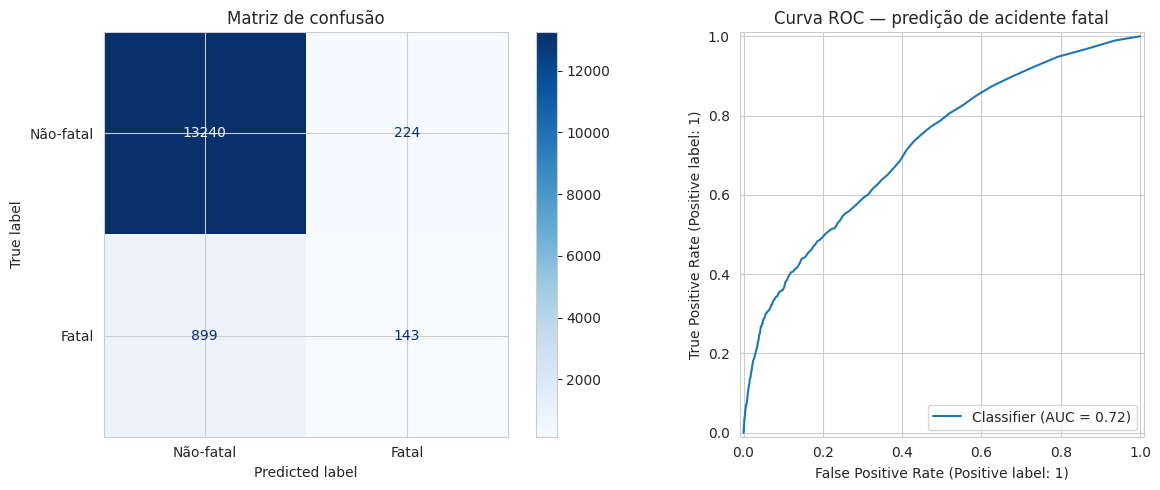

In [ ]:
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred,
      target_names=["Não-fatal", "Fatal"]))
print(f"AUC-ROC: {roc_auc_score(y_test, y_prob):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Não-fatal", "Fatal"],
    cmap="Blues", ax=ax[0])
ax[0].set_title("Matriz de confusão")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1])
ax[1].set_title("Curva ROC — predição de acidente fatal")
plt.tight_layout()
plt.show()

## 10. Ajuste de limiar (threshold)

O corte padrão é 0,5, mas ele pode ser escolhido conforme o objetivo. Para uma
ferramenta preventiva, aceitar mais falsos alarmes em troca de detectar mais
acidentes fatais costuma valer a pena. A tabela abaixo mostra o trade-off.

In [ ]:
limiares = [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]
linhas = []
for t in limiares:
    pred_t = (y_prob >= t).astype(int)
    tp = ((pred_t == 1) & (y_test == 1)).sum()
    fp = ((pred_t == 1) & (y_test == 0)).sum()
    fn = ((pred_t == 0) & (y_test == 1)).sum()
    recall = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    linhas.append({"limiar": t, "recall_fatal": round(recall, 3),
                   "precision_fatal": round(precision, 3),
                   "alertas_emitidos": int(tp + fp)})

tabela_thr = pd.DataFrame(linhas)
print(tabela_thr.to_string(index=False))

 limiar  recall_fatal  precision_fatal  alertas_emitidos
   0.50         0.138            0.380               379
   0.40         0.205            0.337               635
   0.30         0.299            0.293              1064
   0.20         0.378            0.218              1806
   0.15         0.443            0.181              2555
   0.10         0.529            0.147              3746


## 11. Importância dos atributos

Quais fatores mais pesam na predição de um acidente fatal. Material direto para
a discussão do artigo.

/tmp/ipykernel_1597/3537463489.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=imp.values, y=imp.index, palette="Blues_r")


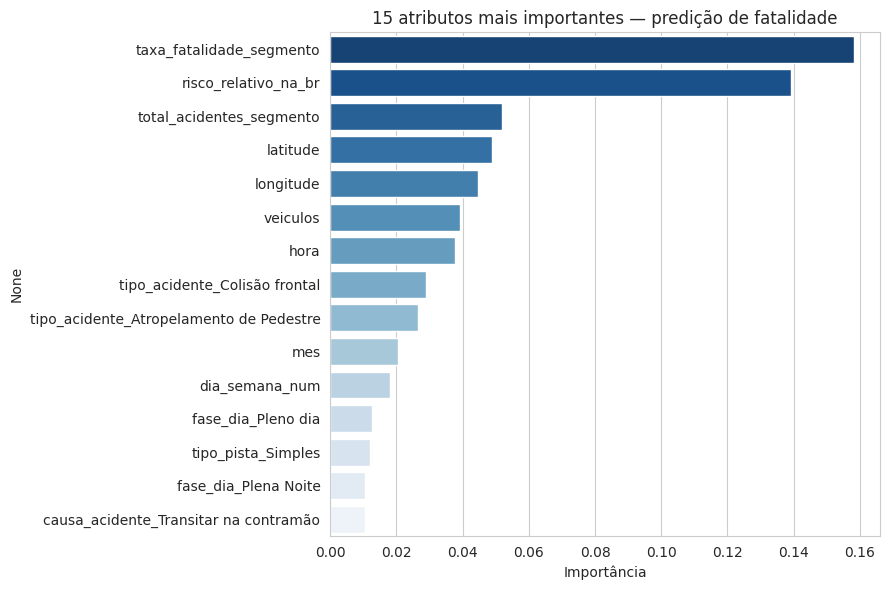

,importancia
taxa_fatalidade_segmento,0.158169
risco_relativo_na_br,0.139121
total_acidentes_segmento,0.051923
latitude,0.049011
longitude,0.044749
veiculos,0.039232
hora,0.037607
tipo_acidente_Colisão frontal,0.028880
tipo_acidente_Atropelamento de Pedestre,0.026474
mes,0.020533


In [ ]:
# Nomes das features após o one-hot
ohe = modelo.named_steps["preprocessador"].named_transformers_["cat"].named_steps["onehot"]
nomes_cat = ohe.get_feature_names_out(features_categoricas)
nomes = list(nomes_cat) + features_numericas

importancias = modelo.named_steps["classificador"].feature_importances_
imp = (pd.Series(importancias, index=nomes)
       .sort_values(ascending=False)
       .head(15))

plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=imp.index, palette="Blues_r")
plt.title("15 atributos mais importantes — predição de fatalidade")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

imp.to_frame("importancia")

## 12. Conclusões da análise exploratória

Cruzamentos que mostram padrões previsíveis de fatalidade — a base conceitual do
SafeRoute. Taxa de fatalidade = proporção de acidentes fatais dentro de cada
categoria (usa a base completa `df`).

In [ ]:
def taxa_fatalidade_por(coluna, min_registros=100):
    g = df.groupby(coluna).agg(
        total=("target_binario", "size"),
        fatais=("target_binario", "sum"),
    )
    g = g[g["total"] >= min_registros]
    g["taxa_fatalidade_%"] = (g["fatais"] / g["total"] * 100).round(2)
    return g.sort_values("taxa_fatalidade_%", ascending=False)

for coluna in ["fase_dia", "tipo_pista", "condicao_meteorologica", "tracado_via"]:
    if coluna in df.columns:
        print("=" * 60)
        print(f"Taxa de fatalidade por: {coluna}")
        print("=" * 60)
        print(taxa_fatalidade_por(coluna).to_string())
        print()

Taxa de fatalidade por: fase_dia
             total  fatais  taxa_fatalidade_%
fase_dia                                     
Amanhecer     3447     386              11.20
Plena Noite  24781    2522              10.18
Anoitecer     3926     253               6.44
Pleno dia    40375    2048               5.07

Taxa de fatalidade por: tipo_pista
            total  fatais  taxa_fatalidade_%
tipo_pista                                  
Simples     34733    3423               9.86
Dupla       30782    1501               4.88
Múltipla     7014     285               4.06

Taxa de fatalidade por: condicao_meteorologica
                        total  fatais  taxa_fatalidade_%
condicao_meteorologica                                  
Nevoeiro/Neblina          553      60              10.85
Ignorado                 1000      99               9.90
Vento                     104       9               8.65
Céu Claro               46375    3418               7.37
Nublado                 11435     830   

/tmp/ipykernel_1597/417783096.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=t, x="taxa_fatalidade_%", y="fase_dia", palette="Reds_r")


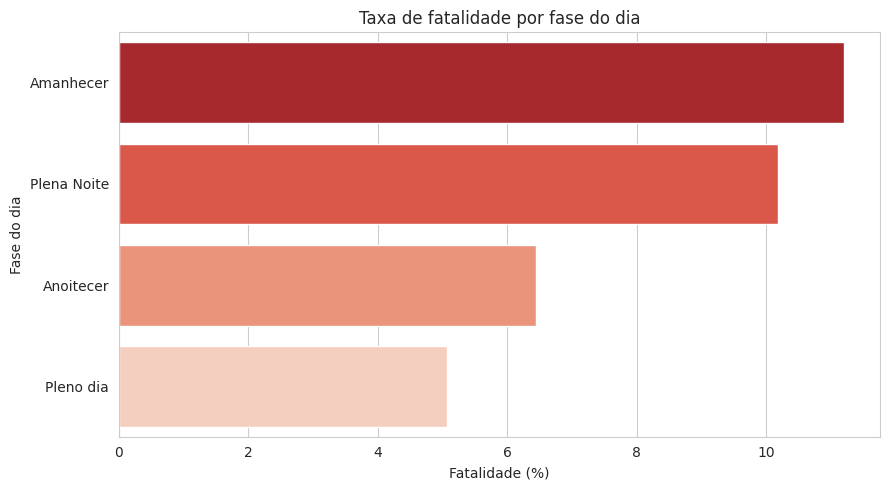

In [ ]:
# Visualização de um dos cruzamentos (fase do dia)
if "fase_dia" in df.columns:
    t = taxa_fatalidade_por("fase_dia").reset_index()
    plt.figure(figsize=(9, 5))
    sns.barplot(data=t, x="taxa_fatalidade_%", y="fase_dia", palette="Reds_r")
    plt.title("Taxa de fatalidade por fase do dia")
    plt.xlabel("Fatalidade (%)")
    plt.ylabel("Fase do dia")
    plt.tight_layout()
    plt.show()

---
### Próximos passos (Sprint 3)

Evoluir da classificação por acidente individual para o **modelo agregado de
risco por segmento**, usando `risco_relativo_na_br` como base do índice de risco
exibido no mapa interativo do SafeRoute.